# Mini Case Study: Retail Store Analysis

## 1. Import the Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. DataFrames

### DataFrame 1: `sales_df`

In [2]:
sales_df = pd.DataFrame({
    "OrderID": [1001, 1002, 1003, 1004, 1005, 1006],
    "Product": ["Notebook", "Pen", "Bag", "Notebook", "Bottle", "Pen"],
    "Quantity": [3, 10, 2, 4, 3, 8],
    "UnitPrice": [50, 10, 600, 50, 150, 10],
    "City": ["Indore", "Bhopal", "Indore", "Ujjain", "Bhopal", "Indore"]
})

### DataFrame 2: `products_df`

In [3]:
products_df = pd.DataFrame({
    "Product": ["Notebook", "Pen", "Bag", "Bottle"],
    "Category": ["Stationery", "Stationery", "Accessories", "Accessories"],
    "Stock": [40, 100, 12, 25],
    "CostPrice": [30, 4, 420, 90]
})

### DataFrame 3: `customers_df`

In [4]:
customers_df = pd.DataFrame({
    "CustomerID": [1, 2, 3, 4, 5],
    "Customer": ["Asha", "Rahul", "Neha", "Aman", "Ira"],
    "City": ["Indore", "Bhopal", "Indore", "Ujjain", "Dewas"],
    "Age": [24, 31, 28, 22, 35]
})

### DataFrame 4: `monthly_sales_df`

In [5]:
monthly_sales_df = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
    "Revenue": [12000, 15000, 13500, 18000, 21000, 19500]
})

### DataFrame 5: `employee_df`

In [6]:
employee_df = pd.DataFrame({
    "Employee": ["Karan", "Pooja", "Sameer", "Divya"],
    "Department": ["Sales", "Support", "Sales", "Inventory"],
    "MonthlySalary": [25000, 22000, 28000, 24000]
})

## 3. Tasks

### 1. Inspect the data (Pandas)
Display the first five rows of `sales_df` and show the number of rows and columns in each of the five DataFrames.

In [7]:
sales_df.head()

,OrderID,Product,Quantity,UnitPrice,City
0,1001,Notebook,3,50,Indore
1,1002,Pen,10,10,Bhopal
2,1003,Bag,2,600,Indore
3,1004,Notebook,4,50,Ujjain
4,1005,Bottle,3,150,Bhopal


In [11]:
print(f'sales_df: (Rows, Columns): {sales_df.shape}')
print(f'products_df: (Rows, Columns): {products_df.shape}')
print(f'customers_df: (Rows, Columns): {customers_df.shape}')
print(f'monthly_sales_df: (Rows, Columns): {monthly_sales_df.shape}')
print(f'employee_df: (Rows, Columns): {employee_df.shape}')

sales_df: (Rows, Columns): (6, 5)
products_df: (Rows, Columns): (4, 4)
customers_df: (Rows, Columns): (5, 4)
monthly_sales_df: (Rows, Columns): (6, 2)
employee_df: (Rows, Columns): (4, 3)


### 2. Create a sales column (Pandas)
In `sales_df`, create `Revenue` using `Quantity × UnitPrice`. Display `OrderID`, `Product`, `Quantity`, and `Revenue`.

In [14]:
sales_df['Revenue'] = sales_df['Quantity'] * sales_df['UnitPrice']
sales_df

,OrderID,Product,Quantity,UnitPrice,City,Revenue
0,1001,Notebook,3,50,Indore,150
1,1002,Pen,10,10,Bhopal,100
2,1003,Bag,2,600,Indore,1200
3,1004,Notebook,4,50,Ujjain,200
4,1005,Bottle,3,150,Bhopal,450
5,1006,Pen,8,10,Indore,80


### 3. Find high-value orders (Pandas)
Display orders whose `Revenue` is greater than or equal to 500. Sort from highest to lowest `Revenue`.

In [15]:
sales_df[sales_df['Revenue'] >= 500]

,OrderID,Product,Quantity,UnitPrice,City,Revenue
2,1003,Bag,2,600,Indore,1200


### 4. Product-wise revenue (Pandas)
Calculate total `Revenue` for each `Product`. Which product generated the highest revenue?

In [16]:
sales_df.groupby('Product')['Revenue'].sum()

Product
Bag         1200
Bottle       450
Notebook     350
Pen          180
Name: Revenue, dtype: int64

### 5. City-wise sales (Pandas)
Calculate total `Revenue` for each `City` and identify the city with the highest revenue.

In [17]:
sales_df.groupby('City')['Revenue'].sum()

City
Bhopal     550
Indore    1430
Ujjain     200
Name: Revenue, dtype: int64

### 6. Low-stock products (Pandas)
From `products_df`, display products with `Stock` less than 30. Show only `Product` and `Stock`.

In [22]:
products_df.loc[products_df['Stock'] <= 30, ['Product', 'Stock']]

,Product,Stock
2,Bag,12
3,Bottle,25


### 7. Profit estimate (Pandas)
Merge `sales_df` with `products_df` on `Product`. Create `Profit` using `(UnitPrice − CostPrice) × Quantity`. Display `Product`, `Quantity`, `Revenue`, and `Profit`.

In [25]:
merged = sales_df.merge(products_df)

merged['Profit'] = (merged['UnitPrice'] - merged['CostPrice']) * merged['Quantity']

merged

,OrderID,Product,Quantity,UnitPrice,City,Revenue,Category,Stock,CostPrice,Profit
0,1001,Notebook,3,50,Indore,150,Stationery,40,30,60
1,1002,Pen,10,10,Bhopal,100,Stationery,100,4,60
2,1003,Bag,2,600,Indore,1200,Accessories,12,420,360
3,1004,Notebook,4,50,Ujjain,200,Stationery,40,30,80
4,1005,Bottle,3,150,Bhopal,450,Accessories,25,90,180
5,1006,Pen,8,10,Indore,80,Stationery,100,4,48


### 8. NumPy calculations
Convert `monthly_sales_df['Revenue']` into a NumPy array. Calculate mean, maximum, minimum, and total revenue using NumPy.

In [31]:
rev = np.array(monthly_sales_df['Revenue'])

print(f'Mean: {rev.mean()}')
print(f'Maximum: {rev.max()}')
print(f'Minimum: {rev.min()}')
print(f'Total Revenue: {rev.sum()}')

Mean: 16500.0
Maximum: 21000
Minimum: 12000
Total Revenue: 99000


### 9. Monthly revenue chart (Matplotlib)
Create a line chart of `Month` versus `Revenue`. Add a title, axis labels, markers, and grid.

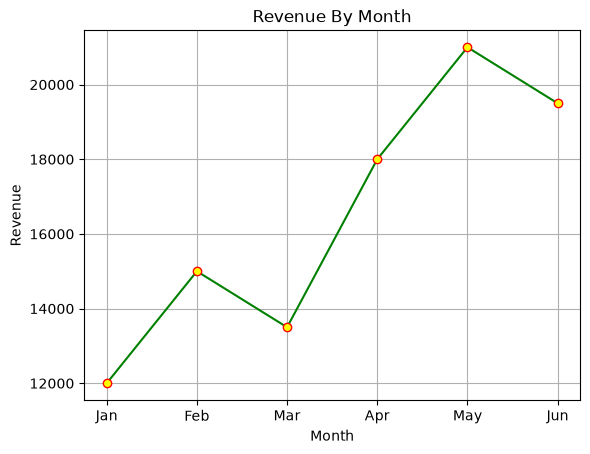

In [48]:
plt.plot(monthly_sales_df['Month'], monthly_sales_df['Revenue'], marker='o', color='green', markerfacecolor='yellow', markeredgecolor='red')
plt.title('Revenue By Month')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid()
plt.show()

### 10. Product revenue chart (Pandas + Matplotlib)
Create a bar chart of total revenue by product. Add a title and axis labels, then write two insights.

In [ ]:
rev_by_product = sales_df.groupby('Product')['Revenue'].sum()
rev_by_product

Product
Bag         1200
Bottle       450
Notebook     350
Pen          180
Name: Revenue, dtype: int64

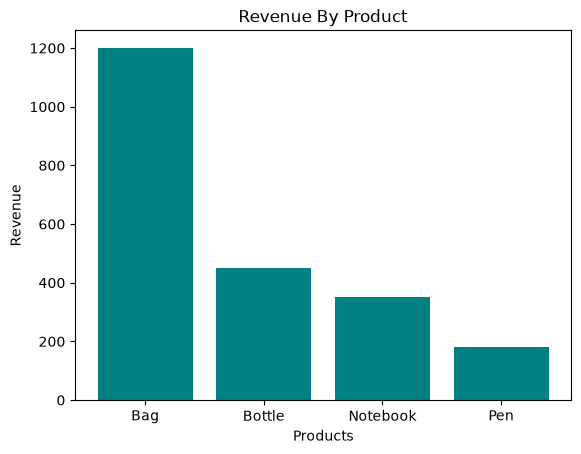

In [58]:
plt.bar(rev_by_product.index,rev_by_product.values, color='teal')
plt.title("Revenue By Product")
plt.xlabel('Products')
plt.ylabel('Revenue')
plt.show()

**Insight 1:** Bag is the top product with ₹1,200 in revenue, followed by Bottle with ₹450. These two accessories bring in most of the store’s total revenue (₹2,180).

**Insight 2:** Notebook earns ₹350, while Pen earns the least at just ₹180, because each pen costs only ₹10.